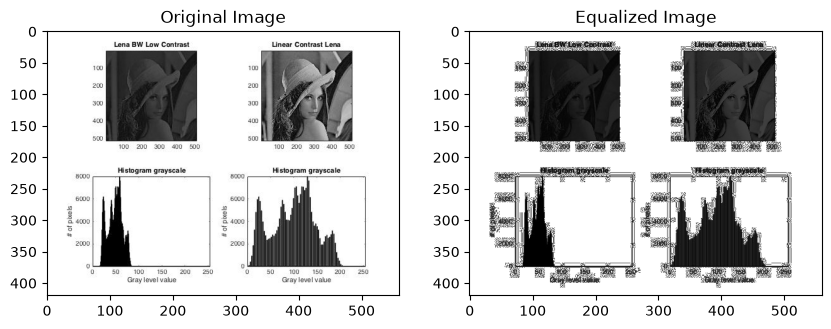

In [1]:
#q1
import cv2
import matplotlib.pyplot as plt

# Load image (grayscale)
img = cv2.imread('input5.jpg', cv2.IMREAD_GRAYSCALE)

# Apply Histogram Equalization
equalized = cv2.equalizeHist(img)

# Show results
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.title("Original Image")
plt.imshow(img, cmap='gray')

plt.subplot(1,2,2)
plt.title("Equalized Image")
plt.imshow(equalized, cmap='gray')

plt.show()

In [2]:
#q2 
import cv2
import numpy as np
from matplotlib import pyplot as plt

def histogram_matching(source, reference):
    src_hist, bins = np.histogram(source.flatten(), 256, [0,256])
    ref_hist, bins = np.histogram(reference.flatten(), 256, [0,256])

    # CDF
    src_cdf = src_hist.cumsum()
    ref_cdf = ref_hist.cumsum()

    # Normalize
    src_cdf = src_cdf / src_cdf.max()
    ref_cdf = ref_cdf / ref_cdf.max()

    # Mapping
    mapping = np.zeros(256)
    for i in range(256):
        diff = np.abs(ref_cdf - src_cdf[i])
        mapping[i] = np.argmin(diff)

    matched = np.interp(source.flatten(), range(256), mapping)
    return matched.reshape(source.shape).astype(np.uint8)

# Load images
src = cv2.imread('input6.jpg', 0)
ref = cv2.imread('reference.jpg', 0)

# Apply matching
matched = histogram_matching(src, ref)

# Display
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Input")
plt.imshow(src, cmap='gray')

plt.subplot(1,3,2)
plt.title("Reference")
plt.imshow(ref, cmap='gray')

plt.subplot(1,3,3)
plt.title("Matched Output")
plt.imshow(matched, cmap='gray')

plt.show()

AttributeError: 'NoneType' object has no attribute 'flatten'

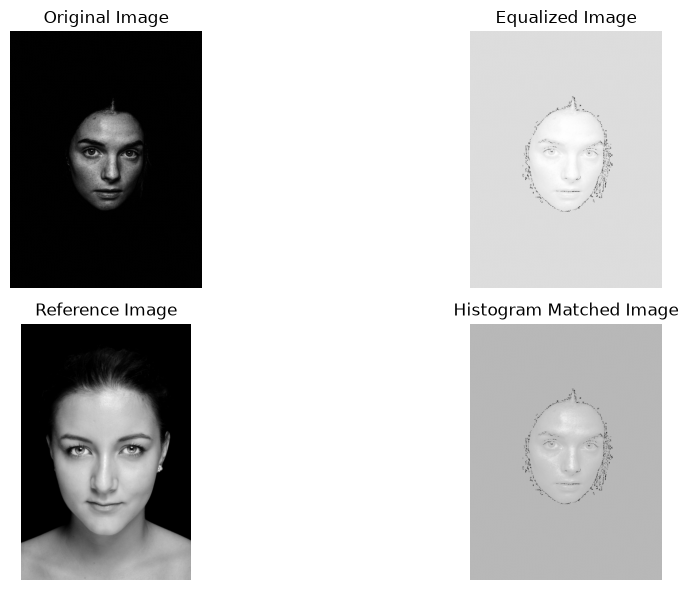

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# -------------------------------
# Load Images (USE FULL PATH)
# -------------------------------
src_path = r'input6.jpg'        # change if needed
ref_path = r'reference1.jpg'     # change if needed

src = cv2.imread(src_path, 0)
ref = cv2.imread(ref_path, 0)

# -------------------------------
# Error Handling (IMPORTANT)
# -------------------------------
if src is None:
    raise ValueError(f"Input image not found at: {src_path}")

if ref is None:
    raise ValueError(f"Reference image not found at: {ref_path}")

# -------------------------------
# 1. HISTOGRAM EQUALIZATION
# -------------------------------
equalized = cv2.equalizeHist(src)

# -------------------------------
# 2. HISTOGRAM MATCHING FUNCTION
# -------------------------------
def histogram_matching(source, reference):

    # Compute histograms
    src_hist, _ = np.histogram(source.flatten(), 256, [0,256])
    ref_hist, _ = np.histogram(reference.flatten(), 256, [0,256])

    # Compute CDF
    src_cdf = src_hist.cumsum()
    ref_cdf = ref_hist.cumsum()

    # Normalize
    src_cdf = src_cdf / src_cdf.max()
    ref_cdf = ref_cdf / ref_cdf.max()

    # Create mapping
    mapping = np.zeros(256, dtype=np.uint8)

    for i in range(256):
        diff = np.abs(ref_cdf - src_cdf[i])
        mapping[i] = np.argmin(diff)

    # Apply mapping
    matched = mapping[source]

    return matched

# -------------------------------
# Apply Histogram Matching
# -------------------------------
matched = histogram_matching(src, ref)

# -------------------------------
# Display Results
# -------------------------------
plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
plt.title("Original Image")
plt.imshow(src, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title("Equalized Image")
plt.imshow(equalized, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3)
plt.title("Reference Image")
plt.imshow(ref, cmap='gray')
plt.axis('off')

plt.subplot(2,2,4)
plt.title("Histogram Matched Image")
plt.imshow(matched, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()